In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Create sample customer data
customers_data = {
    "customer_id": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    "customer_name": [
        "Rahul", "Priya", "Amit", "Sneha", "Kiran",
        "Anjali", "Vikram", "Neha", "Arjun", "Pooja"
    ],
    "city": [
        "Hyderabad", "Bengaluru", "Hyderabad", "Chennai", "Mumbai",
        "Bengaluru", "Mumbai", "Chennai", "Hyderabad", "Pune"
    ],
    "region": [
        "South", "South", "South", "South", "West",
        "South", "West", "South", "South", "West"
    ]
}

customers = pd.DataFrame(customers_data)

# Create sample order data
orders_data = {
    "order_id": [
        1001, 1002, 1003, 1004, 1005,
        1006, 1007, 1008, 1009, 1010,
        1011, 1012, 1013, 1014, 1015
    ],
    "customer_id": [
        101, 102, 101, 103, 104,
        105, 102, 106, 107, 101,
        108, 103, 109, 105, 102
    ],
    "order_amount": [
        2500, 4000, 1500, 3000, 2200,
        5000, 1800, 3500, 1200, 4500,
        2800, 2000, 3200, 1500, 2200
    ]
}

orders = pd.DataFrame(orders_data)

# Save the datasets as CSV files
customers.to_csv("customers.csv", index=False)
orders.to_csv("orders.csv", index=False)

print("Sample CSV files created successfully!")
print("\nCustomers dataset:")
display(customers.head())

print("\nOrders dataset:")
display(orders.head())

Sample CSV files created successfully!

Customers dataset:


,customer_id,customer_name,city,region
0,101,Rahul,Hyderabad,South
1,102,Priya,Bengaluru,South
2,103,Amit,Hyderabad,South
3,104,Sneha,Chennai,South
4,105,Kiran,Mumbai,West



Orders dataset:


,order_id,customer_id,order_amount
0,1001,101,2500
1,1002,102,4000
2,1003,101,1500
3,1004,103,3000
4,1005,104,2200


In [3]:
# Load the CSV files
customers = pd.read_csv("customers.csv")
orders = pd.read_csv("orders.csv")

print("Customers shape:", customers.shape)
print("Orders shape:", orders.shape)

print("\nCustomer columns:")
print(customers.columns.tolist())

print("\nOrder columns:")
print(orders.columns.tolist())

Customers shape: (10, 4)
Orders shape: (15, 3)

Customer columns:
['customer_id', 'customer_name', 'city', 'region']

Order columns:
['order_id', 'customer_id', 'order_amount']


In [4]:
# INNER JOIN
inner_join = pd.merge(
    customers,
    orders,
    on="customer_id",
    how="inner"
)

print("INNER JOIN RESULT:")
display(inner_join)

print("Total matching order records:", len(inner_join))

INNER JOIN RESULT:


,customer_id,customer_name,city,region,order_id,order_amount
0,101,Rahul,Hyderabad,South,1001,2500
1,101,Rahul,Hyderabad,South,1003,1500
2,101,Rahul,Hyderabad,South,1010,4500
3,102,Priya,Bengaluru,South,1002,4000
4,102,Priya,Bengaluru,South,1007,1800
5,102,Priya,Bengaluru,South,1015,2200
6,103,Amit,Hyderabad,South,1004,3000
7,103,Amit,Hyderabad,South,1012,2000
8,104,Sneha,Chennai,South,1005,2200
9,105,Kiran,Mumbai,West,1006,5000


Total matching order records: 15


In [5]:
# LEFT JOIN
left_join = pd.merge(
    customers,
    orders,
    on="customer_id",
    how="left"
)

print("LEFT JOIN RESULT:")
display(left_join)

print("Total rows after LEFT JOIN:", len(left_join))

LEFT JOIN RESULT:


,customer_id,customer_name,city,region,order_id,order_amount
0,101,Rahul,Hyderabad,South,1001.0,2500.0
1,101,Rahul,Hyderabad,South,1003.0,1500.0
2,101,Rahul,Hyderabad,South,1010.0,4500.0
3,102,Priya,Bengaluru,South,1002.0,4000.0
4,102,Priya,Bengaluru,South,1007.0,1800.0
5,102,Priya,Bengaluru,South,1015.0,2200.0
6,103,Amit,Hyderabad,South,1004.0,3000.0
7,103,Amit,Hyderabad,South,1012.0,2000.0
8,104,Sneha,Chennai,South,1005.0,2200.0
9,105,Kiran,Mumbai,West,1006.0,5000.0


Total rows after LEFT JOIN: 16


In [6]:
# Aggregate order information for each customer
customer_metrics = (
    orders.groupby("customer_id")
    .agg(
        total_spend=("order_amount", "sum"),
        average_order_value=("order_amount", "mean"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

# Join customer details with the calculated metrics
customer_insights = pd.merge(
    customers,
    customer_metrics,
    on="customer_id",
    how="left"
)

# Replace missing metrics for customers with no purchases
metric_columns = [
    "total_spend",
    "average_order_value",
    "total_orders"
]

customer_insights[metric_columns] = (
    customer_insights[metric_columns].fillna(0)
)

# Format metric columns
customer_insights["total_orders"] = (
    customer_insights["total_orders"].astype(int)
)

customer_insights["total_spend"] = (
    customer_insights["total_spend"].round(2)
)

customer_insights["average_order_value"] = (
    customer_insights["average_order_value"].round(2)
)

print("CUSTOMER BUSINESS KPIs:")
display(customer_insights)

CUSTOMER BUSINESS KPIs:


,customer_id,customer_name,city,region,total_spend,average_order_value,total_orders
0,101,Rahul,Hyderabad,South,8500.0,2833.33,3
1,102,Priya,Bengaluru,South,8000.0,2666.67,3
2,103,Amit,Hyderabad,South,5000.0,2500.00,2
3,104,Sneha,Chennai,South,2200.0,2200.00,1
4,105,Kiran,Mumbai,West,6500.0,3250.00,2
5,106,Anjali,Bengaluru,South,3500.0,3500.00,1
6,107,Vikram,Mumbai,West,1200.0,1200.00,1
7,108,Neha,Chennai,South,2800.0,2800.00,1
8,109,Arjun,Hyderabad,South,3200.0,3200.00,1
9,110,Pooja,Pune,West,0.0,0.00,0


In [7]:
# Add customer location information to orders
orders_with_location = pd.merge(
    orders,
    customers[["customer_id", "city", "region"]],
    on="customer_id",
    how="left"
)

# City-level analysis
city_analysis = (
    orders_with_location.groupby("city")
    .agg(
        total_sales=("order_amount", "sum"),
        total_orders=("order_id", "nunique"),
        average_order_value=("order_amount", "mean")
    )
    .reset_index()
    .sort_values("total_sales", ascending=False)
)

print("CITY-WISE BUSINESS ANALYSIS:")
display(city_analysis.round(2))

# Region-level analysis
region_analysis = (
    orders_with_location.groupby("region")
    .agg(
        total_sales=("order_amount", "sum"),
        total_orders=("order_id", "nunique"),
        average_order_value=("order_amount", "mean")
    )
    .reset_index()
    .sort_values("total_sales", ascending=False)
)

print("REGION-WISE BUSINESS ANALYSIS:")
display(region_analysis.round(2))

CITY-WISE BUSINESS ANALYSIS:


,city,total_sales,total_orders,average_order_value
2,Hyderabad,16700,6,2783.33
0,Bengaluru,11500,4,2875.00
3,Mumbai,7700,3,2566.67
1,Chennai,5000,2,2500.00


REGION-WISE BUSINESS ANALYSIS:


,region,total_sales,total_orders,average_order_value
0,South,33200,12,2766.67
1,West,7700,3,2566.67


In [8]:
# Keep only customers who have made at least one purchase
active_customers = customer_insights[
    customer_insights["total_orders"] > 0
].copy()

print("Customers who made purchases:", len(active_customers))
print(
    "Customers with zero purchases:",
    len(customer_insights) - len(active_customers)
)

print("\nACTIVE CUSTOMERS:")
display(active_customers)

Customers who made purchases: 9
Customers with zero purchases: 1

ACTIVE CUSTOMERS:


,customer_id,customer_name,city,region,total_spend,average_order_value,total_orders
0,101,Rahul,Hyderabad,South,8500.0,2833.33,3
1,102,Priya,Bengaluru,South,8000.0,2666.67,3
2,103,Amit,Hyderabad,South,5000.0,2500.00,2
3,104,Sneha,Chennai,South,2200.0,2200.00,1
4,105,Kiran,Mumbai,West,6500.0,3250.00,2
5,106,Anjali,Bengaluru,South,3500.0,3500.00,1
6,107,Vikram,Mumbai,West,1200.0,1200.00,1
7,108,Neha,Chennai,South,2800.0,2800.00,1
8,109,Arjun,Hyderabad,South,3200.0,3200.00,1


In [9]:
# Keep only customers who have made at least one purchase
active_customers = customer_insights[
    customer_insights["total_orders"] > 0
].copy()

print("Customers who made purchases:", len(active_customers))
print(
    "Customers with zero purchases:",
    len(customer_insights) - len(active_customers)
)

print("\nACTIVE CUSTOMERS:")
display(active_customers)

Customers who made purchases: 9
Customers with zero purchases: 1

ACTIVE CUSTOMERS:


,customer_id,customer_name,city,region,total_spend,average_order_value,total_orders
0,101,Rahul,Hyderabad,South,8500.0,2833.33,3
1,102,Priya,Bengaluru,South,8000.0,2666.67,3
2,103,Amit,Hyderabad,South,5000.0,2500.00,2
3,104,Sneha,Chennai,South,2200.0,2200.00,1
4,105,Kiran,Mumbai,West,6500.0,3250.00,2
5,106,Anjali,Bengaluru,South,3500.0,3500.00,1
6,107,Vikram,Mumbai,West,1200.0,1200.00,1
7,108,Neha,Chennai,South,2800.0,2800.00,1
8,109,Arjun,Hyderabad,South,3200.0,3200.00,1


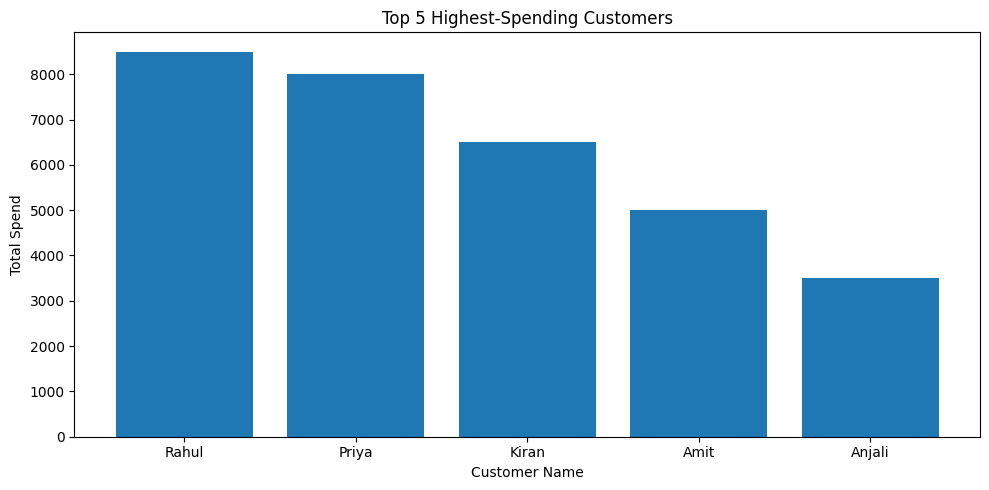

In [11]:
# Calculate top 5 highest-spending customers
top_5_customers = customer_insights.nlargest(5, "total_spend")

# Plot the data
plt.figure(figsize=(10, 5))
plt.bar(
    top_5_customers["customer_name"],
    top_5_customers["total_spend"]
)

plt.title("Top 5 Highest-Spending Customers")
plt.xlabel("Customer Name")
plt.ylabel("Total Spend")
plt.tight_layout()
plt.show()

In [12]:
# Save all important analysis outputs
inner_join.to_csv("inner_join_results.csv", index=False)
left_join.to_csv("left_join_results.csv", index=False)
customer_insights.to_csv("customer_insights.csv", index=False)
city_analysis.to_csv("city_analysis.csv", index=False)
region_analysis.to_csv("region_analysis.csv", index=False)
top_5_customers.to_csv("top_5_customers.csv", index=False)

print("All analysis output files saved successfully!")

All analysis output files saved successfully!


In [15]:
# Create a copy and add a Rank column
readme_table = top_5_customers.copy()
readme_table["rank"] = range(1, len(top_5_customers) + 1)

# Subset and reorder columns
readme_table = readme_table[
    [
        "rank",
        "customer_id",
        "customer_name",
        "city",
        "region",
        "total_orders",
        "total_spend",
        "average_order_value"
    ]
]

readme_table.columns = [
    "Rank",
    "Customer ID",
    "Customer Name",
    "City",
    "Region",
    "Total Orders",
    "Total Spend",
    "Average Order Value"
]

print(readme_table.to_markdown(index=False))

|   Rank |   Customer ID | Customer Name   | City      | Region   |   Total Orders |   Total Spend |   Average Order Value |
|-------:|--------------:|:----------------|:----------|:---------|---------------:|--------------:|----------------------:|
|      1 |           101 | Rahul           | Hyderabad | South    |              3 |          8500 |               2833.33 |
|      2 |           102 | Priya           | Bengaluru | South    |              3 |          8000 |               2666.67 |
|      3 |           105 | Kiran           | Mumbai    | West     |              2 |          6500 |               3250    |
|      4 |           103 | Amit            | Hyderabad | South    |              2 |          5000 |               2500    |
|      5 |           106 | Anjali          | Bengaluru | South    |              1 |          3500 |               3500    |


In [16]:
%pip install tabulate

In [17]:
import pandas as pd
from google.colab import files

customers_data = {
    "customer_id": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    "customer_name": [
        "Rahul", "Priya", "Amit", "Sneha", "Kiran",
        "Anjali", "Vikram", "Neha", "Arjun", "Pooja"
    ],
    "city": [
        "Hyderabad", "Bengaluru", "Hyderabad", "Chennai", "Mumbai",
        "Bengaluru", "Mumbai", "Chennai", "Hyderabad", "Pune"
    ],
    "region": [
        "South", "South", "South", "South", "West",
        "South", "West", "South", "South", "West"
    ]
}

customers = pd.DataFrame(customers_data)

customers.to_csv("customers.csv", index=False)

files.download("customers.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
import pandas as pd
from google.colab import files

orders_data = {
    "order_id": list(range(1001, 1016)),
    "customer_id": [
        101, 102, 101, 103, 104,
        105, 102, 106, 107, 101,
        108, 103, 109, 105, 102
    ],
    "order_amount": [
        2500, 4000, 1500, 3000, 2200,
        5000, 1800, 3500, 1200, 4500,
        2800, 2000, 3200, 1500, 2200
    ]
}

orders = pd.DataFrame(orders_data)

orders.to_csv("orders.csv", index=False)

files.download("orders.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
from google.colab import files

readme_content = f"""# E-Commerce Customer Insights Engine

## Project Overview

This project analyzes e-commerce customer and order data
using Python and Pandas.

**Note:** The datasets used in this demonstration are sample
data created for educational purposes.

## Objectives

1. Perform INNER JOIN and LEFT JOIN using Pandas.
2. Calculate total spending per customer.
3. Calculate average order value (AOV).
4. Analyze sales by city and region.
5. Identify customers with zero purchases.
6. Generate a leaderboard of the Top 5 highest-spending customers.

## Technologies Used

- Python
- Google Colab
- Pandas
- Matplotlib

## Top 5 Highest-Spending Customers

{readme_table.to_markdown(index=False)}

## Files

- customers.csv: Customer information.
- orders.csv: Order transaction records.
- E-Commerce_Customer_Insights_Engine.ipynb: Executed analysis notebook.

## Conclusion

The project demonstrates relational joins, customer segmentation,
business KPI calculations, and identification of high-value customers.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>